# Поиск по документации Matplotlib, Blender и QGIS

Задача — по исходному вопросу пользователя найти страницу, которую процитировали в принятом ответе. Проверяем два фактора: способ текстового поиска и добавление изображений со стороны вопроса и документации.

Источники: [Matplotlib 3.10.7](https://matplotlib.org/3.10.7/), [Blender 4.5](https://docs.blender.org/manual/en/4.5/modeling/geometry_nodes/index.html), [QGIS 3.44](https://docs.qgis.org/3.44/en/docs/). По умолчанию таблицы и графики пересчитываются по сохранённой выдаче. Для повторного inference переключите флаг в первой ячейке и подготовьте веса и изображения по [инструкции](README.md). Окружение — `.venv`, зависимости — в `requirements.lock`.

In [1]:
import gzip
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

root = Path.cwd()
if not (root / "scripts" / "retrieval.py").exists():
    root = root / "multimodal-documentation-qa"
sys.path.insert(0, str(root / "scripts"))
from zipfile import ZipFile
from collect import read_questions

rerun_inference = False

domains = {"matplotlib": "Matplotlib", "blender": "Blender", "qgis": "QGIS"}
data = root / "data"
pd.set_option("display.max_colwidth", 85)
pd.options.display.float_format = "{:,.1f}".format
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

## Вопросы и разметка

Период — 2021–2025 годы по дате вопроса, UTC. Площадки и теги: Stack Overflow (`matplotlib`), Blender Stack Exchange (`geometry-nodes`), GIS Stack Exchange (`qgis` и `raster` вместе). У каждого вопроса проверены ID принятого ответа и флаг принятия.

Берём только ссылки на страницы зафиксированной английской версии документации. Якоря отбрасываем. Из целевых страниц исключаем уже указанные в вопросе. Если целей несколько, сохраняем все. Для Matplotlib отбираем 100 вопросов с максимальным рейтингом и 100 случайных из остатка (seed 42). Для двух других корпусов берём все подходящие вопросы. Наличие картинки на отбор не влияет.

In [2]:
def read_json(path):
    if path.suffix == ".gz":
        with gzip.open(path, "rt", encoding="utf-8") as stream:
            return json.load(stream)
    return json.loads(path.read_text())

records = read_questions()
questions = pd.DataFrame(records)
selection = {key: read_json(data / f"{key}-selection.json") for key in domains}
assert not questions.duplicated(["site", "id"]).any()
assert questions.accepted.all()
assert all(r["targets"] and not set(r["targets"]).intersection(r["question_doc_pages"]) for r in records)

pd.DataFrame([{
    "Корпус": name, "С принятым ответом": selection[key]["seen_accepted_questions"],
    "Со ссылкой по условиям": selection[key]["eligible"], "В датасете": selection[key]["selected"],
    "Пар вопрос–страница": sum(len(r["targets"]) for r in records if r["domain"] == key)
} for key, name in domains.items()]).set_index("Корпус")

,С принятым ответом,Со ссылкой по условиям,В датасете,Пар вопрос–страница
Корпус,,,,
Matplotlib,9806,1518,200,257
Blender,3018,106,106,144
QGIS,272,46,46,64


In [3]:
sample = questions.assign(
    выборка=questions.group.map({"popular":"выше рейтинг", "random_remaining":"остаток"}),
    год=pd.to_datetime(questions.creation_date, unit="s", utc=True).dt.year,
    с_картинкой=questions.images.map(bool)
)
sample.groupby(["domain", "выборка"]).agg(
    Вопросы=("id", "size"), Медиана_рейтинга=("score", "median"),
    С_картинкой=("с_картинкой", "sum"), Первый_год=("год", "min"), Последний_год=("год", "max")
)

Вопросы  Медиана_рейтинга  С_картинкой  Первый_год  \
domain     выборка                                                            
blender    выше рейтинг       53               5.0           40        2021   
           остаток            53               1.0           47        2022   
matplotlib выше рейтинг      100               4.0           63        2021   
           остаток           100               1.0           55        2021   
qgis       выше рейтинг       23               4.0            9        2021   
           остаток            23               2.0            6        2021   

                         Последний_год  
domain     выборка                      
blender    выше рейтинг           2025  
           остаток                2025  
matplotlib выше рейтинг           2025  
           остаток                2025  
qgis       выше рейтинг           2025  
           остаток                2025

Ссылка из принятого ответа — наблюдаемый ориентир для проверки поиска. Она может вести на пример или подробности решения. Другие подходящие страницы в разметке могут отсутствовать. Доли ниже относятся к решённым вопросам с такой ссылкой. В Blender и QGIS две подгруппы вместе исчерпывают доступную совокупность. «Остаток» в Matplotlib — случайные 100 вопросов после отбора ста популярных.

## Что приложено к вопросу

,Вопросов,Только текст,С блоком кода,С картинкой,С кодом и картинкой,Картинка доступна модели
Корпус,,,,,,
Matplotlib,200,10,72,15,103,115
Blender,106,19,0,87,0,86
QGIS,46,27,4,14,1,15


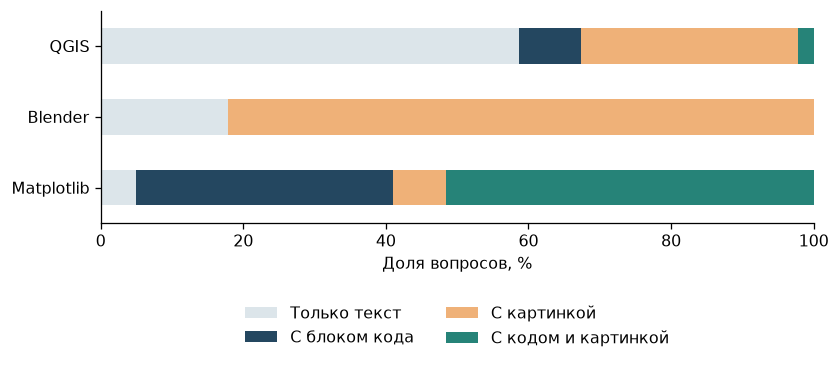

In [4]:
corpora = {key: read_json(data / f"{key}-corpus.json.gz") for key in domains}
questions["code_block"] = questions.code.str.strip().ne("")
questions["image"] = questions.images.map(bool)
questions["usable_image"] = [
    any(url in corpora[key]["available_assets"] for url in urls[:2])
    for key, urls in zip(questions.domain, questions.images)
]
forms = []
for key, name in domains.items():
    g = questions.loc[questions.domain.eq(key)]
    forms.append({"Корпус": name, "Вопросов": len(g), "Только текст": (~g.image & ~g.code_block).sum(),
                  "С блоком кода": (~g.image & g.code_block).sum(), "С картинкой": (g.image & ~g.code_block).sum(),
                  "С кодом и картинкой": (g.image & g.code_block).sum(),
                  "Картинка доступна модели": g.usable_image.sum()})
formats = pd.DataFrame(forms).set_index("Корпус")
display(formats)
columns = ["Только текст", "С блоком кода", "С картинкой", "С кодом и картинкой"]
ax = formats[columns].div(formats["Вопросов"], axis=0).mul(100).plot.barh(
    stacked=True, color=["#dce5ea","#244760","#efb178","#268378"], figsize=(8, 2.4))
ax.set(xlabel="Доля вопросов, %", ylabel="", xlim=(0, 100))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.32), ncol=2, frameon=False)
plt.show()

Четыре категории взаимоисключающие. В «только текст» входят и строчные фрагменты кода. Блок кода — непустой HTML-элемент `pre`; он может содержать traceback. Изображение — встроенный `img`. Для локальных моделей берём до двух доступных изображений из первых двух вложений. Маленькие значки и неподдерживаемые источники пропускаем.

## Документация и иллюстрации

Для каждого продукта собрана одна общая коллекция кандидатов: все целевые страницы, до 100 случайных тематических страниц и ближайшая по заголовку страница для каждого вопроса (символьный TF–IDF). Каждому вопросу доступны все страницы коллекции его продукта. Это закрытая проверка поиска внутри заведомо покрывающего корпуса. Метрики нельзя напрямую переносить на поиск по всему сайту.

HTML разделён по заголовкам и далее на блоки до 115 слов. В текст входят подписи и alt-текст. Для визуального режима берём до двух доступных иллюстраций на страницу из первых трёх подходящих URL. Изображение привязывается к первому блоку своего раздела, не более одного на блок.

In [5]:
structures = {key: read_json(data / f"{key}-structure.json.gz") for key in domains}
inventory = []
for key, name in domains.items():
    corpus = corpora[key]
    pages = corpus["pages"]
    figures = [p for p in structures[key] if "error" not in p]
    gold = {t for r in records if r["domain"] == key for t in r["targets"]}
    inventory.append({
        "Корпус": name, "Страницы": len(pages), "Цели доступны": len(gold & {p["slug"] for p in pages}),
        "Всего целей": len(gold), "Фрагменты": sum(len(p["chunks"]) for p in pages),
        "Страницы с иллюстрацией в индексе": sum(any(c["assets"] for c in p["chunks"]) for p in pages),
        "Блоки figure": sum(p["figure_blocks"] for p in figures),
        "Из них с подписью": sum(p["captioned"] for p in figures),
        "Страницы со ссылкой на figure": sum(p["exact_figure_links"] > 0 for p in figures),
        "Абзацы с текстовым маркером": sum(p["paragraph_markers"] for p in figures),
        "Межстраничные связи": sum(len(p["outlinks"]) for p in figures),
    })
display(pd.DataFrame(inventory).set_index("Корпус").T)

Корпус,Matplotlib,Blender,QGIS
Страницы,355,181,127
Цели доступны,149,82,22
Всего целей,149,82,22
Фрагменты,3921,1105,4584
Страницы с иллюстрацией в индексе,275,156,84
Блоки figure,63,289,902
Из них с подписью,4,117,472
Страницы со ссылкой на figure,0,1,23
Абзацы с текстовым маркером,12,7,73
Межстраничные связи,7608,548,400


Ссылка на рисунок засчитана, если HTML-якорь ведёт на блок `figure` своей страницы или его дочерний элемент. Выражения вроде *as shown below* считаются отдельно как текстовые маркеры. Межстраничная связь — уникальная для исходной страницы ссылка на другую страницу справочника из основного содержимого. Это задел для Graph RAG; графовый поиск здесь не запускался.

## Sparse и dense retrieval

**Sparse retrieval (BM25).** Ищем фрагменты документации по словам из вопроса и кода. Параметры BM25 — `k1=1.2` и `b=0.75`.

**Dense retrieval (BGE).** Для вопроса и каждого фрагмента берём embedding токена `[CLS]` и ранжируем фрагменты по cosine similarity. Лимит — 160 токенов. [BGE-small-en-v1.5](https://huggingface.co/BAAI/bge-small-en-v1.5)

Оба метода получают один и тот же запрос и ищут по одним и тем же фрагментам. Оценка страницы равна максимальной оценке её фрагмента.

**Hit@5** — доля вопросов, для которых в первой пятёрке есть хотя бы одна целевая страница. **Recall@5** учитывает все целевые страницы вопроса. **MRR@10** — средний обратный ранг первого совпадения в десятке (ноль при промахе).

In [6]:
from contextlib import redirect_stdout
from io import StringIO

if rerun_inference:
    from retrieval import evaluate
    with redirect_stdout(StringIO()):
        evaluated = {key: evaluate(key) for key in domains}
else:
    evaluated = {key: read_json(data / f"{key}-rankings.json") for key in domains}

results = pd.DataFrame([
    {"domain": key, "id": row["id"], "query_image": row["query_image"],
     "target_image": row["target_image"], "method": method,
     "hit5": score["hit5"], "recall5": score["recall5"], "rr10": score["rr10"]}
    for key, rows in evaluated.items() for row in rows for method, score in row["methods"].items()
])
assert (results.groupby(["domain", "id"]).size() == 6).all()
text = results[results.method.isin(["BM25", "BGE"])]
text.groupby(["domain", "method"]).agg(
    n=("id", "size"), Hit5=("hit5", "mean"), Recall5=("recall5", "mean"), MRR10=("rr10", "mean")
).assign(Hit5=lambda x: 100*x.Hit5, Recall5=lambda x: 100*x.Recall5,
         MRR10=lambda x: 100*x.MRR10).rename(columns={"Hit5":"Hit@5, %","Recall5":"Recall@5, %","MRR10":"MRR@10 × 100"})

n  Hit@5, %  Recall@5, %  MRR@10 × 100
domain     method                                          
blender    BGE     106      29.2         26.4          22.6
           BM25    106      33.0         29.8          22.4
matplotlib BGE     200      39.5         34.8          24.0
           BM25    200      26.0         22.3          14.2
qgis       BGE      46      37.0         33.7          24.1
           BM25     46      32.6         29.0          22.5

## Изображение вопроса и иллюстрация раздела

Один и тот же [CLIP ViT-B/32](https://huggingface.co/openai/clip-vit-base-patch32) работает в четырёх режимах. У CLIP лимит 77 токенов. Текст и формат кандидатов одинаковы во всех четырёх режимах. При добавлении изображений смешиваются нормированные векторы текста и изображения с равным весом, затем результат снова нормируется. Для нескольких картинок вопроса сначала усредняются их векторы. Если картинки нет, сохраняется исходный текстовый вектор.

| Режим | Вопрос | Документация |
|---|---|---|
| A | Текст и код | Текст и подписи |
| B | Текст, код и картинка | Текст и подписи |
| C | Текст и код | Текст, подписи и иллюстрация |
| D | Текст, код и картинка | Текст, подписи и иллюстрация |

BGE и CLIP по-разному кодируют текст и поддерживают разную длину запроса. Эффект добавления пикселей оценивается сравнением режимов внутри CLIP.

режим,A,B,C,D
Корпус,,,,
blender,19.8,18.9,20.8,15.1
matplotlib,16.5,17.0,18.5,14.5
qgis,13.0,15.2,13.0,10.9


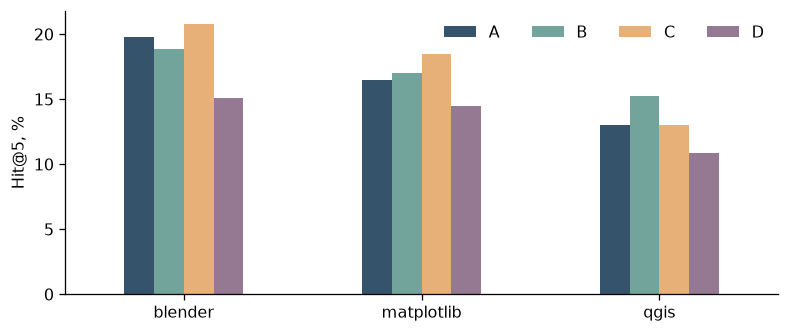

In [7]:
clip = results[results.method.str.startswith("CLIP")].copy()
clip["режим"] = clip.method.str[-1]
hits = clip.pivot(index=["domain", "id", "query_image", "target_image"], columns="режим", values="hit5")
display((100 * hits.groupby(level="domain").mean()).rename_axis("Корпус").round(1))
ax = (hits.groupby(level="domain").mean()*100).plot.bar(
    figsize=(8, 3.2), rot=0, color=["#35536b","#72a49b","#e6b078","#957892"])
ax.set(xlabel="", ylabel="Hit@5, %")
ax.legend(ncols=4, frameon=False)
plt.show()

In [8]:
def paired(group, mode, subset):
    diff = (group[mode] - group["A"]).to_numpy()
    if len(diff) == 0:
        return {"Срез": subset, "Сравнение": mode + "−A", "n": 0}
    draws = np.random.default_rng(42).choice(diff, (3000, len(diff))).mean(axis=1)
    lo, hi = np.quantile(draws, [.025, .975])
    return {"Срез": subset, "Сравнение": mode + "−A", "n": len(diff),
            "Вошла в топ-5": int((diff>0).sum()), "Выпала": int((diff<0).sum()),
            "Δ, п.п.": 100*diff.mean(), "95% интервал, п.п.": f"[{100*lo:.1f}; {100*hi:.1f}]"}

effects = []
for key in domains:
    g = hits.xs(key, level="domain")
    cases = [(g, "D", "Все"), (g[g.index.get_level_values("query_image")], "B", "С картинкой вопроса"),
             (g[g.index.get_level_values("target_image")], "C", "С иллюстрацией цели")]
    effects.extend({"Корпус": domains[key], **paired(part, mode, label)} for part,mode,label in cases)
display(pd.DataFrame(effects).set_index(["Корпус", "Срез"]))

Сравнение    n  Вошла в топ-5  Выпала  Δ, п.п.  \
Корпус     Срез                                                                 
Matplotlib Все                       D−A  200             10      14     -2.0   
           С картинкой вопроса       B−A  115              6       5      0.9   
           С иллюстрацией цели       C−A  178              6       2      2.2   
Blender    Все                       D−A  106              7      12     -4.7   
           С картинкой вопроса       B−A   86              5       6     -1.2   
           С иллюстрацией цели       C−A   97              2       1      1.0   
QGIS       Все                       D−A   46              0       1     -2.2   
           С картинкой вопроса       B−A   15              1       0      6.7   
           С иллюстрацией цели       C−A   35              0       0      0.0   

                               95% интервал, п.п.  
Корпус     Срез                                    
Matplotlib Все                        [-7.0; 3.0]  
           С картинкой вопроса        [-4.3; 6.1]  
           С иллюстрацией цели        [-0.6; 5.6]  
Blender    Все                       [-13.2; 3.8]  
           С картинкой вопроса        [-8.1; 7.0]  
           С иллюстрацией цели        [-2.1; 5.2]  
QGIS       Все                        [-6.5; 0.0]  
           С картинкой вопроса        [0.0; 20.0]  
           С иллюстрацией цели         [0.0; 0.0]

95%-й интервал для разницы Hit@5 рассчитан методом paired bootstrap по вопросам (3 000 повторов). B−A показывает вклад картинки пользователя на вопросах с доступной картинкой. C−A приведён для вопросов, у которых хотя бы одна целевая страница представлена с иллюстрацией. D−A — общий эффект на всей выборке. Отрицательная разница означает, что в этом режиме добавление изображений ухудшило воспроизведение ссылок.

## Qwen3-VL-Embedding-2B

Повторяем A–D на тех же 352 вопросах и 663 страницах. Списки фрагментов, картинки, targets и правило max по странице совпадают с экспериментом CLIP. В Qwen инструкция, изображения и текст поступают на вход совместно. Embedding — нормированный hidden state последнего токена после применения chat template модели. Размер — 2 048.

Официальные веса загружены локально и проверены по SHA-256. Inference — PyTorch, Metal (MPS), FP16. Для запроса используем retrieval-инструкцию, для фрагмента — стандартную инструкцию модели. Лимит исходного текста — 512 токенов до добавления шаблона и visual tokens; в A и B остаётся один и тот же текст, как и в C и D для документа. Под этот лимит обрезаны 40 из 352 вопросов и 2 из 9 610 фрагментов. Изображения берём из прежнего локального снимка. CLIP получает crop 224 × 224, а Qwen обрабатывает те же файлы своим image processor с сохранением пропорций. Разницу Qwen и CLIP определяют в том числе эти настройки и разные лимиты длины текста. Результаты по вопросам сохраняются в `data/*-qwen-rankings.json`, embeddings — в локальном кеше. [Checkpoint](https://huggingface.co/Qwen/Qwen3-VL-Embedding-2B/tree/9f2f7e710d6d81056aa5c0a4f04764fec6bb7bda).

Для загрузки этой же ревизии на другой машине предусмотрена команда `python scripts/weights.py --qwen`. При повторном запуске эксперимента используются локальные embeddings.

In [9]:
if rerun_inference:
    from qwen_retrieval import run as run_qwen
    with redirect_stdout(StringIO()):
        qwen_rows = run_qwen(tuple(domains))
else:
    qwen_rows = {key: read_json(data / f"{key}-qwen-rankings.json") for key in domains}

previous = {(r["domain"], r["id"]): r for rows in evaluated.values() for r in rows}
qwen_by_id = {(r["domain"], r["id"]): r for rows in qwen_rows.values() for r in rows}
assert qwen_by_id.keys() == previous.keys()
assert all(set(r["targets"]) == set(previous[k]["targets"]) for k, r in qwen_by_id.items())

qwen = pd.DataFrame([
    {"domain": k[0], "id": k[1], "method": f"Qwen {mode}", "hit5": s["hit5"],
     "recall5": s["recall5"], "rr10": s["rr10"], "query_image": previous[k]["query_image"],
     "target_image": previous[k]["target_image"]}
    for k, r in qwen_by_id.items() for mode, s in r["methods"].items()
])
comparison = pd.concat([results, qwen], ignore_index=True)
hit_matrix = comparison.pivot(index=["domain", "id"], columns="method", values="hit5")
methods = ["BGE", "CLIP A", "Qwen A", "CLIP B", "Qwen B", "CLIP C", "Qwen C", "CLIP D", "Qwen D"]
display((hit_matrix[methods].groupby(level="domain").mean() * 100).rename_axis("Hit@5, %"))
qwen_metrics = qwen.groupby(["domain", "method"])[["hit5", "recall5", "rr10"]].mean().mul(100)
display(qwen_metrics.rename(columns={"hit5": "Hit@5, %", "recall5": "Recall@5, %", "rr10": "MRR@10 × 100"}))

method,BGE,CLIP A,Qwen A,CLIP B,Qwen B,CLIP C,Qwen C,CLIP D,Qwen D
"Hit@5, %",,,,,,,,,
blender,29.2,19.8,34.0,18.9,33.0,20.8,34.9,15.1,34.9
matplotlib,39.5,16.5,48.5,17.0,47.0,18.5,48.5,14.5,48.5
qgis,37.0,13.0,65.2,15.2,63.0,13.0,65.2,10.9,63.0


Hit@5, %  Recall@5, %  MRR@10 × 100
domain     method                                     
blender    Qwen A      34.0         31.4          26.1
           Qwen B      33.0         29.6          24.4
           Qwen C      34.9         33.3          24.3
           Qwen D      34.9         32.0          23.2
matplotlib Qwen A      48.5         42.5          30.0
           Qwen B      47.0         41.0          29.7
           Qwen C      48.5         42.0          31.0
           Qwen D      48.5         42.0          29.7
qgis       Qwen A      65.2         57.6          43.0
           Qwen B      63.0         55.4          43.7
           Qwen C      65.2         57.6          45.1
           Qwen D      63.0         55.4          45.8

### Парное сравнение

B−A оценивает вклад картинки пользователя среди вопросов с доступным изображением. C−A — вклад иллюстраций документации среди вопросов с иллюстрацией хотя бы на одной целевой странице. D−A, сравнения с CLIP D и BGE считаются по всем вопросам соответствующего продукта. Для разницы Hit@5 указаны число улучшений и ухудшений и 95%-й интервал (paired bootstrap, 3 000 повторов).

n  Выигрыши  Проигрыши  Δ, п.п.  \
Корпус     Сравнение                                                   
Matplotlib B−A · картинка вопроса  115         5          8     -2.6   
           C−A · иллюстрация цели  178         1          1      0.0   
           D−A · все               200         6          6      0.0   
           Qwen D − CLIP D         200        73          5     34.0   
           Qwen A − BGE            200        35         17      9.0   
           Qwen D − BGE            200        36         18      9.0   
Blender    B−A · картинка вопроса   86         2          3     -1.2   
           C−A · иллюстрация цели   97         1          1      0.0   
           D−A · все               106         4          3      0.9   
           Qwen D − CLIP D         106        26          5     19.8   
           Qwen A − BGE            106        11          6      4.7   
           Qwen D − BGE            106        12          6      5.7   
QGIS       B−A · картинка вопроса   15         0          1     -6.7   
           C−A · иллюстрация цели   35         0          0      0.0   
           D−A · все                46         0          1     -2.2   
           Qwen D − CLIP D          46        25          1     52.2   
           Qwen A − BGE             46        14          1     28.3   
           Qwen D − BGE             46        14          2     26.1   

                                  95% интервал, п.п.  
Корпус     Сравнение                                  
Matplotlib B−A · картинка вопроса        [-8.7, 3.5]  
           C−A · иллюстрация цели        [-1.7, 1.7]  
           D−A · все                     [-3.5, 3.5]  
           Qwen D − CLIP D              [26.5, 41.5]  
           Qwen A − BGE                  [2.0, 16.0]  
           Qwen D − BGE                  [2.0, 16.0]  
Blender    B−A · картинка вопроса        [-7.0, 3.5]  
           C−A · иллюстрация цели        [-3.1, 3.1]  
           D−A · все                     [-3.8, 5.7]  
           Qwen D − CLIP D              [10.4, 29.2]  
           Qwen A − BGE                 [-2.8, 12.3]  
           Qwen D − BGE                 [-1.9, 13.2]  
QGIS       B−A · картинка вопроса       [-20.0, 0.0]  
           C−A · иллюстрация цели         [0.0, 0.0]  
           D−A · все                     [-6.5, 0.0]  
           Qwen D − CLIP D              [37.0, 67.4]  
           Qwen A − BGE                 [13.0, 43.5]  
           Qwen D − BGE                 [10.9, 41.3]

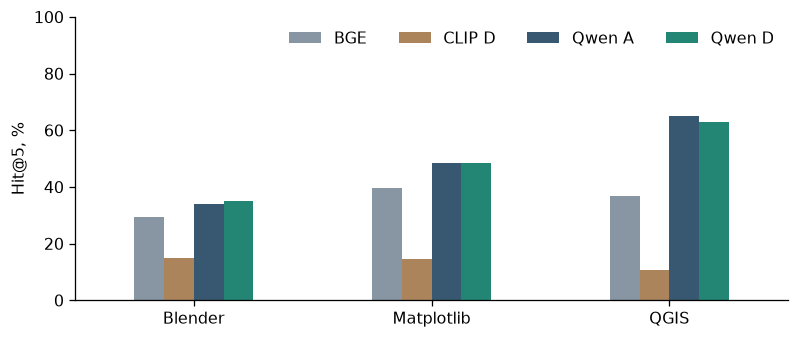

In [10]:
def paired_hit5(frame, base, candidate, label):
    diff = (frame[candidate] - frame[base]).to_numpy()
    draws = np.random.default_rng(42).choice(diff, (3000, len(diff))).mean(axis=1)
    lo, hi = np.quantile(draws, [.025, .975]) * 100
    return {"Сравнение": label, "n": len(diff), "Выигрыши": int((diff > 0).sum()),
            "Проигрыши": int((diff < 0).sum()), "Δ, п.п.": diff.mean()*100,
            "95% интервал, п.п.": f"[{lo:.1f}, {hi:.1f}]"}

pairs = []
for key, label in domains.items():
    subset = hit_matrix.xs(key, level="domain")
    flags = qwen[(qwen.domain == key) & (qwen.method == "Qwen A")].set_index("id")
    tests = [(subset.loc[flags.index[flags.query_image]], "Qwen A", "Qwen B", "B−A · картинка вопроса"),
             (subset.loc[flags.index[flags.target_image]], "Qwen A", "Qwen C", "C−A · иллюстрация цели"),
             (subset, "Qwen A", "Qwen D", "D−A · все"),
             (subset, "CLIP D", "Qwen D", "Qwen D − CLIP D"),
             (subset, "BGE", "Qwen A", "Qwen A − BGE"),
             (subset, "BGE", "Qwen D", "Qwen D − BGE")]
    pairs.extend({"Корпус": label, **paired_hit5(frame, base, cand, title)}
                 for frame, base, cand, title in tests)
display(pd.DataFrame(pairs).set_index(["Корпус", "Сравнение"]))

ax = (hit_matrix[["BGE", "CLIP D", "Qwen A", "Qwen D"]]
      .groupby(level="domain").mean().mul(100).rename(index=domains)
      .plot.bar(figsize=(8, 3.2), rot=0, color=["#8895a3", "#ab845c", "#375870", "#238674"]))
ax.set(xlabel="", ylabel="Hit@5, %", ylim=(0, 100))
ax.legend(ncols=4, frameon=False)
plt.show()

## Пример выдачи

Показываем первый по ID вопрос Matplotlib с доступной картинкой, для которого A и D дали разные результаты Hit@5. Этот выбор иллюстрирует смену выдачи; частоты улучшений и ухудшений приведены выше.

**[Adding a Rectangle Patch and Text Patch to 3D Collection in Matplotlib](https://stackoverflow.com/questions/66738036/adding-a-rectangle-patch-and-text-patch-to-3d-collection-in-matplotlib)** · [Принятый ответ](https://stackoverflow.com/a/66747967)

Целевые страницы: [faq](https://matplotlib.org/3.10.7/api/toolkits/mplot3d/faq.html)

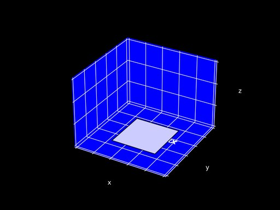

,Первая страница,Цель в топ-5
Метод,,
BM25,api/_as_gen/mpl_toolkits.mplot3d.art3d.pathpatch_2d_to_3d,False
BGE,api/_as_gen/matplotlib.patches.Rectangle,False
CLIP A,gallery/text_labels_and_annotations/text_rotation_relative_to_line,True
CLIP D,gallery/images_contours_and_fields/image_zcoord,False


Фрагмент в начале выдачи BGE:

matplotlib.patches.Rectangle. class matplotlib.patches. Rectangle ( xy , width , height , * , angle = 0.0 , rotation_point = 'xy' , ** kwargs ) [source] Bases: Patch A rectangle defined via an anchor point xy and its width and height . The rectangle extends from xy[0] to xy[0] + width in x-direction and from xy[1] to xy[1] + height in y-direction. : +------------------+ : | | : height | : | | : ( 


In [11]:
items = sorted(evaluated["matplotlib"], key=lambda r: r["id"])
changed = [r for r in items if r["query_image"] and r["methods"]["CLIP A"]["hit5"] != r["methods"]["CLIP D"]["hit5"]]
item = (changed or [r for r in items if r["query_image"]] or items)[0]
example = next(r for r in records if r["domain"] == "matplotlib" and r["id"] == item["id"])
display(Markdown(f"**[{example['title']}]({example['url']})** · [Принятый ответ]({example['answer_url']})"))
display(Markdown("Целевые страницы: " + ", ".join(
    f"[{slug.split('/')[-1]}]({url})" for slug,url in zip(example["targets"],example["target_urls"]))))
assets = corpora["matplotlib"]["available_assets"]
for url in example["images"][:2]:
    if url in assets:
        with ZipFile(data / "assets.zip") as archive, archive.open(assets[url]) as source, Image.open(source) as img:
            img.thumbnail((450, 210))
            display(img.copy())
        break
display(pd.DataFrame([{"Метод": m, "Первая страница": item["methods"][m]["top10"][0],
                       "Цель в топ-5": bool(item["methods"][m]["hit5"])}
                      for m in ("BM25", "BGE", "CLIP A", "CLIP D")]).set_index("Метод"))
display(Markdown("Фрагмент в начале выдачи BGE:"))
print(item["methods"]["BGE"]["top1_chunk"][:400])

## Итоги

In [12]:
summary = []
for key, label in domains.items():
    g = hit_matrix.xs(key, level="domain").mean()*100
    summary.append(f"**{label}.** Qwen A — {g['Qwen A']:.1f}%, Qwen D — {g['Qwen D']:.1f}% "
                   f"по Hit@5 (изменение {g['Qwen D']-g['Qwen A']:+.1f} п.п.). "
                   f"CLIP D — {g['CLIP D']:.1f}%, текстовый BGE — {g['BGE']:.1f}%.")
overall_change = hit_matrix["Qwen D"] - hit_matrix["Qwen A"]
summary.append(f"По всем {len(overall_change)} вопросам переход Qwen A → D добавил целевую страницу "
               f"в топ-5 для {int((overall_change > 0).sum())} вопросов и вывел её из топ-5 для "
               f"{int((overall_change < 0).sum())}.")
display(Markdown(chr(10).join(chr(10) + line for line in summary)))


**Matplotlib.** Qwen A — 48.5%, Qwen D — 48.5% по Hit@5 (изменение +0.0 п.п.). CLIP D — 14.5%, текстовый BGE — 39.5%.

**Blender.** Qwen A — 34.0%, Qwen D — 34.9% по Hit@5 (изменение +0.9 п.п.). CLIP D — 15.1%, текстовый BGE — 29.2%.

**QGIS.** Qwen A — 65.2%, Qwen D — 63.0% по Hit@5 (изменение -2.2 п.п.). CLIP D — 10.9%, текстовый BGE — 37.0%.

По всем 352 вопросам переход Qwen A → D добавил целевую страницу в топ-5 для 10 вопросов и вывел её из топ-5 для 10.

Выводы относятся к выбранным версиям справочников и к вопросам с явными ссылками в принятом ответе. В эксперименте проверяется поиск страницы. Качество сгенерированного ответа и необходимость изображения для человека требуют отдельной оценки. У CLIP 95%-й интервал изменения D−A включает ноль во всех трёх корпусах. Для Qwen эффект изображений показан отдельно в парном сравнении. Сравнение Qwen D с текстовым BGE одновременно меняет модель и входные данные. Текст на скриншотах, мелкие элементы интерфейса и схемы узлов могли теряться при приведении картинок к входному размеру CLIP 224 × 224.

Данные и списки целей находятся в `data/questions.jsonl`, топ-10 по каждому методу — в `data/*-rankings.json` (в том числе `*-qwen-rankings.json`). Локальные веса: [BGE ONNX](https://huggingface.co/Xenova/bge-small-en-v1.5/tree/ea104dacec62c0de699686887e3f920caeb4f3e3), [CLIP ONNX](https://huggingface.co/Xenova/clip-vit-base-patch32/tree/6b7c523703ae26e39be4b03774966f8571c7f523).

## Чаще ли Qwen ошибается в вопросах с изображениями?

Промах — в топ-5 нет ни одной страницы, указанной в принятом ответе. Группы определены по наличию встроенной картинки в исходном посте. Основное сравнение — **Qwen A**: все 352 вопроса обработаны как текст. Так можно измерить, связана ли частота промахов с типом вопроса. В Qwen D у модели доступны и изображения.

Исходные top-10 уже сохранены. Для этой проверки заново вычисляется только индикатор попадания по ссылкам.

С картинкой  Промахи с картинкой, % Без картинки  \
Режим Корпус                                                        
A     Matplotlib      66/118                    55.9        37/82   
      Blender          58/87                    66.7        12/19   
      QGIS              7/15                    46.7         9/31   
      Все            131/220                    59.5       58/132   
D     Matplotlib      67/118                    56.8        36/82   
      Blender          57/87                    65.5        12/19   
      QGIS              8/15                    53.3         9/31   
      Все            132/220                    60.0       57/132   

                  Промахи без картинки, %  Разница, п.п.  
Режим Корпус                                              
A     Matplotlib                     45.1           10.8  
      Blender                        63.2            3.5  
      QGIS                           29.0           17.6  
      Все                            43.9           15.6  
D     Matplotlib                     43.9           12.9  
      Blender                        63.2            2.4  
      QGIS                           29.0           24.3  
      Все                            43.2           16.8

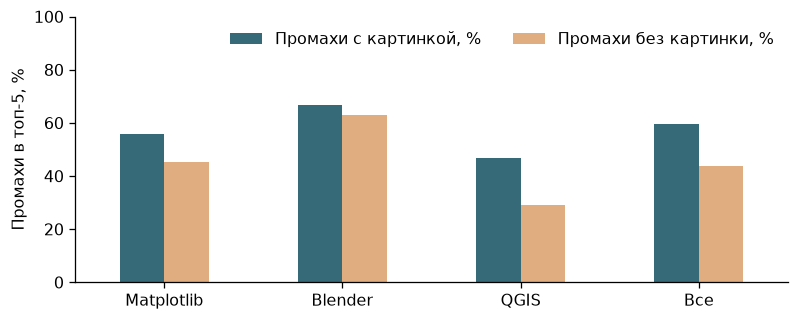

In [13]:
from error_metrics import load_questions, misses, standardized_gap, paired_comparison

image_errors = load_questions()
assert len(image_errors) == 352 and not image_errors.duplicated(["domain","id"]).any()
subsets = [(label, image_errors.loc[image_errors.domain.eq(key)]) for key, label in domains.items()]
by_image = []
for mode in ("A", "D"):
    for label, group in subsets + [("Все", image_errors)]:
        bad_i, n_i, bad_t, n_t = misses(group, mode, "raw_image")
        by_image.append({"Режим":mode, "Корпус":label, "С картинкой":f"{bad_i}/{n_i}",
                         "Промахи с картинкой, %":100*bad_i/n_i, "Без картинки":f"{bad_t}/{n_t}",
                         "Промахи без картинки, %":100*bad_t/n_t, "Разница, п.п.":100*(bad_i/n_i-bad_t/n_t)})
by_image = pd.DataFrame(by_image)
display(by_image.set_index(["Режим","Корпус"]).round(1))
ax = (by_image[by_image["Режим"].eq("A")].set_index("Корпус")
      [["Промахи с картинкой, %","Промахи без картинки, %"]]
      .plot.bar(rot=0, color=["#376a78","#dfad7f"], figsize=(8,3)))
ax.set(xlabel="", ylabel="Промахи в топ-5, %", ylim=(0,100))
ax.legend(frameon=False, ncols=2)
plt.show()

### Поправка на состав выборки

У каждого продукта своя доля скриншотов и своя сложность retrieval. Разницу частот промахов рассчитываем внутри шести групп «продукт × группа по рейтингу», затем усредняем с весами этих групп в выборке. 95%-й интервал получен с помощью bootstrap внутри каждой группы с сохранением числа вопросов с картинкой и без неё. Двусторонний permutation test сохраняет также число промахов в каждой группе (20 000 повторов, seed 42). Оценки относятся к этой выборке решённых вопросов со ссылками.

In [14]:
association_rows = []
for mode, field in [("A","raw_image"), ("D","raw_image"), ("A","usable_image")]:
    for controls, label in [((), "Без поправки"), (("domain","group"), "Продукт × рейтинг")]:
        association_rows.append({"Режим":mode,
                                 "Признак":"Картинка в посте" if field=="raw_image" else "Картинка доступна модели",
                                 "Поправка":label,
                                 **standardized_gap(image_errors, mode, field, controls)})
association = pd.DataFrame(association_rows)
display(association.set_index(["Режим","Признак","Поправка"]).style.format(
    {"Δ, п.п.":"{:.1f}","95% low":"{:.1f}","95% high":"{:.1f}","p (перестановки)":"{:.3f}"}))
usable = image_errors[image_errors.usable_image]
paired_image = paired_comparison(usable, "B", "A")
display(pd.DataFrame([paired_image], index=["B − A, картинка вопроса"]).style.format(
    {"Δ, п.п.":"{:+.1f}","95% low":"{:.1f}","95% high":"{:.1f}","p (McNemar exact)":"{:.3f}"}))

,n,Вошла,Выпала,"Δ, п.п.",95% low,95% high,p (McNemar exact)
"B − A, картинка вопроса",216,7,12,-2.3,-6.5,1.4,0.359


В режиме A промахов больше среди вопросов с картинкой во всех трёх продуктах. Общая разница — **15,6 п.п.**, после поправки — **12,4 п.п.** (95%-й интервал от 0,8 до 23,7 п.п.). Возможные объяснения включают сложность запроса, неполное текстовое описание и выбор страницы, которую процитировал автор ответа.

Отдельное парное сравнение B−A отвечает на другой вопрос: как меняется поиск, если открыть модели изображение того же пользователя. Из 220 постов с изображениями для 216 имелась пригодная картинка. Её передача помогла в 7 случаях и помешала в 12; в 197 случаях Hit@5 не изменился. Изменение Hit@5 — **−2,3 п.п.**, 95%-й интервал от −6,5 до +1,4 п.п.